# 01 — Note-sequence whistle detector (prototype)

Two stages, matching the planned deployment:

1. **Device gate (ESP32, runs 24/7).** Per 32 ms frame: is there one sharp, isolated tone in the
   whistle band? Contiguous tonal frames become *notes* (median pitch, duration); notes close in
   time become an *event*. Only events with ≥ 3 notes are forwarded. Cheap: one 512-point FFT
   every 16 ms and a few comparisons.
2. **Server check (Home Assistant host, only on forwarded events).** Convert the note pitches to
   intervals in semitones (transposition-invariant) and compare with each pattern's template.
   Accept only within a tight tolerance; everything else is rejected.

Data: `data/default/*.wav|json`, pulled from the whistle-lab server (not committed). Recorded on a
phone at 48 kHz; resampled here to 16 kHz to match the ESP32's likely mic rate.

In [1]:
import json, os, pathlib
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly

plt.rcParams.update({"figure.dpi": 80, "font.size": 9})

DATA = pathlib.Path(os.environ.get("WHISTLE_DATA_DIR", "../data")) / "default"
FS = 16_000
NFFT, HOP = 512, 256          # 32 ms window, 16 ms hop, 31 Hz bins

BAND = (700, 4000)            # speech harmonics live below; his whistles are 0.9–1.9 kHz
MIN_PROMINENCE_DB = 20        # peak over in-band median
MIN_CONCENTRATION = 0.5       # fraction of in-band power within ±2 bins of the peak
MAX_SUBHARMONIC_DB = -10      # power at f/2 or f/3 relative to f: speech has it, whistles don't

NOTE_SPLIT_ST = 1.0           # a pitch jump bigger than this starts a new note
MAX_BRIDGE_FRAMES = 3         # dropouts up to 48 ms don't end a note
MIN_NOTE_S = 0.08
MERGE_GAP_S = 0.15            # same-pitch notes separated by less than this are one note
EVENT_END_S = 0.5             # this much silence ends an event
MIN_NOTES_TO_FORWARD = 3

TOL_ST = 1.5                  # server: max |interval error| for a match
NOTE_DUR_S = (0.08, 1.5)

In [2]:
def load(root):
    recs = []
    for p in sorted(root.glob("*.json")):
        meta = json.loads(p.read_text())
        fs, x = wavfile.read(p.with_suffix(".wav"))
        recs.append(dict(label=meta["label"], id=meta["id"],
                         x=resample_poly(x.astype(np.float32) / 32768, FS, fs)))
    order = ["Lights on", "Lights off", "Background noise", "Talking"]
    return sorted(recs, key=lambda r: (order.index(r["label"]), r["id"]))

recs = load(DATA)
PATTERNS = ["Lights on", "Lights off"]
print({l: sum(r["label"] == l for r in recs) for l in dict.fromkeys(r["label"] for r in recs)})

{'Lights on': 5, 'Lights off': 4, 'Background noise': 3, 'Talking': 3}


## Stage 1a — per-frame tonal gate

Three features, all cheap from one power spectrum:

- **prominence**: peak power over the in-band median (dB). Rejects broadband noise.
- **concentration**: fraction of in-band power within ±2 bins of the peak. A whistle puts nearly
  everything in one line; a harmonic stack spreads it.
- **sub-harmonic ratio**: power at f/2 or f/3 relative to the peak. If the peak is the 2nd/3rd
  harmonic of a voice, the fundamental is there; for a whistle it isn't.

In [3]:
def frame_features(x):
    n = 1 + (len(x) - NFFT) // HOP
    frames = np.lib.stride_tricks.sliding_window_view(x, NFFT)[::HOP][:n] * np.hanning(NFFT)
    P = np.abs(np.fft.rfft(frames, axis=1)) ** 2 + 1e-14
    f = np.fft.rfftfreq(NFFT, 1 / FS)
    lo, hi = np.searchsorted(f, BAND)
    Pb, rows = P[:, lo:hi], np.arange(n)
    k = Pb.argmax(1)

    kk = np.clip(k, 1, Pb.shape[1] - 2)
    a, b, c = (np.log(Pb[rows, kk + d]) for d in (-1, 0, 1))
    with np.errstate(invalid="ignore", divide="ignore"):
        delta = np.nan_to_num(np.clip(0.5 * (a - c) / (a - 2 * b + c), -0.5, 0.5))
    freq = f[lo + kk] + delta * FS / NFFT

    csum = np.concatenate([np.zeros((n, 1)), np.cumsum(Pb, 1)], 1)
    near = csum[rows, np.minimum(k + 3, Pb.shape[1])] - csum[rows, np.maximum(k - 2, 0)]
    kf = lo + k
    sub = np.maximum(P[rows, np.round(kf / 2).astype(int)], P[rows, np.round(kf / 3).astype(int)])

    feat = dict(
        t=(rows * HOP + NFFT / 2) / FS, freq=freq,
        prominence=10 * np.log10(Pb.max(1) / np.median(Pb, 1)),
        concentration=near / csum[:, -1],
        subharmonic=10 * np.log10(sub / P[rows, kf]),
        S=10 * np.log10(P.T), f=f,
    )
    feat["tonal"] = ((feat["prominence"] > MIN_PROMINENCE_DB)
                     & (feat["concentration"] > MIN_CONCENTRATION)
                     & (feat["subharmonic"] < MAX_SUBHARMONIC_DB))
    return feat

for r in recs:
    r["feat"] = frame_features(r["x"])

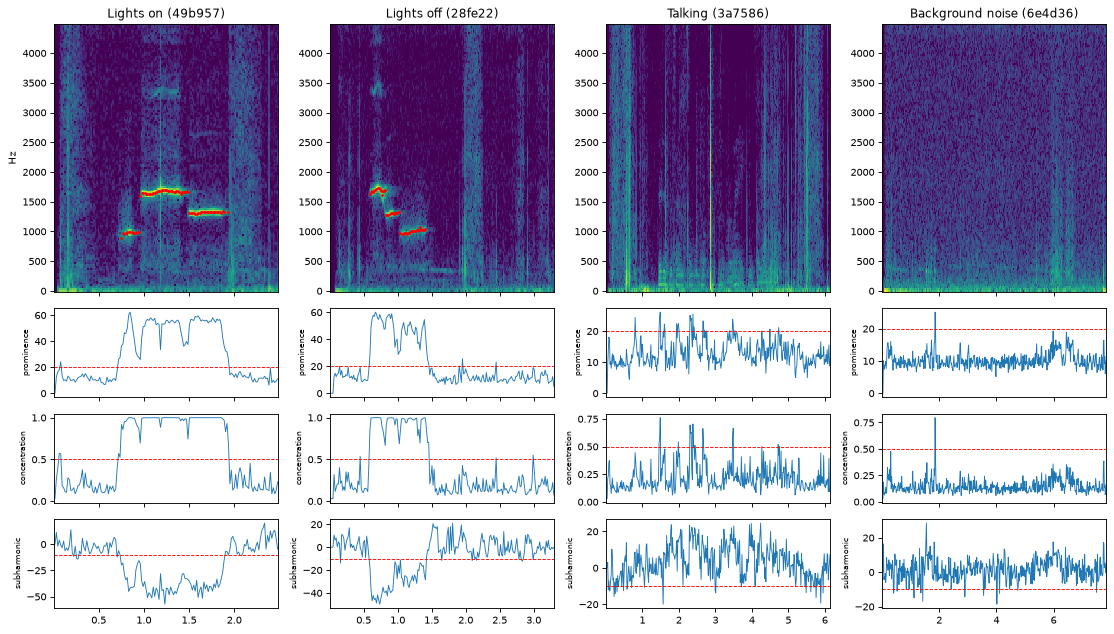

In [4]:
examples = [next(r for r in recs if r["label"] == l) for l in ["Lights on", "Lights off", "Talking", "Background noise"]]
fig, axes = plt.subplots(4, len(examples), figsize=(14, 8), sharex="col",
                         gridspec_kw=dict(height_ratios=[3, 1, 1, 1]))
for col, r in zip(axes.T, examples):
    F = r["feat"]
    band = F["f"] < 4500
    col[0].pcolormesh(F["t"], F["f"][band], F["S"][band], shading="auto",
                      vmin=F["S"][band].max() - 70, vmax=F["S"][band].max())
    col[0].plot(F["t"][F["tonal"]], F["freq"][F["tonal"]], "r.", ms=3)
    col[0].set_title(f'{r["label"]} ({r["id"][-6:]})')
    for ax, key, thr in zip(col[1:], ["prominence", "concentration", "subharmonic"],
                            [MIN_PROMINENCE_DB, MIN_CONCENTRATION, MAX_SUBHARMONIC_DB]):
        ax.plot(F["t"], F[key], lw=0.8)
        ax.axhline(thr, color="r", ls="--", lw=0.8)
        ax.set_ylabel(key, fontsize=7)
axes[0, 0].set_ylabel("Hz")
fig.tight_layout()

Distribution of the features over every frame, by recording label. The gate needs all three; the
sub-harmonic ratio is what removes speech that survives the other two.

Lights on         tonal frames: 56.2%
Lights off        tonal frames: 35.8%
Background noise  tonal frames: 0.0%
Talking           tonal frames: 1.0%


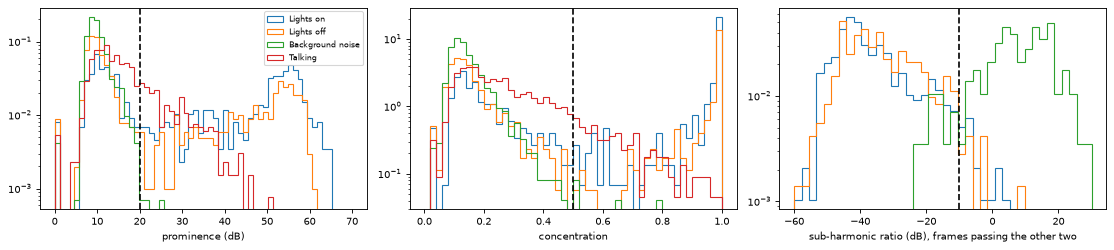

In [5]:
groups = {l: [r for r in recs if r["label"] == l] for l in dict.fromkeys(r["label"] for r in recs)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
pre = lambda F: (F["prominence"] > MIN_PROMINENCE_DB) & (F["concentration"] > MIN_CONCENTRATION)
for label, rs in groups.items():
    P = np.concatenate([r["feat"]["prominence"] for r in rs])
    C = np.concatenate([r["feat"]["concentration"] for r in rs])
    Sh = np.concatenate([r["feat"]["subharmonic"][pre(r["feat"])] for r in rs])
    axes[0].hist(P, bins=60, range=(0, 70), histtype="step", density=True, label=label)
    axes[1].hist(C, bins=50, range=(0, 1), histtype="step", density=True, label=label)
    if len(Sh) > 5:
        axes[2].hist(Sh, bins=40, range=(-60, 30), histtype="step", density=True, label=label)
for ax, thr, name in zip(axes, [MIN_PROMINENCE_DB, MIN_CONCENTRATION, MAX_SUBHARMONIC_DB],
                         ["prominence (dB)", "concentration", "sub-harmonic ratio (dB), frames passing the other two"]):
    ax.axvline(thr, color="k", ls="--"); ax.set_xlabel(name); ax.set_yscale("log")
axes[0].legend(fontsize=7)
fig.tight_layout()

for label, rs in groups.items():
    print(f"{label:17s} tonal frames: {np.mean(np.concatenate([r['feat']['tonal'] for r in rs])):.1%}")

## Stage 1b — notes and events

In [6]:
@dataclass
class Note:
    start: float
    end: float
    freq: float

    @property
    def dur(self):
        return self.end - self.start


def semitones(f1, f0):
    return 12 * np.log2(f1 / f0)


def segment_notes(F):
    t, freq, tonal = F["t"], F["freq"], F["tonal"]
    notes, cur, gap = [], [], 0

    def close():
        if cur and t[cur[-1]] - t[cur[0]] + HOP / FS >= MIN_NOTE_S:
            notes.append(Note(t[cur[0]], t[cur[-1]] + HOP / FS, float(np.median(freq[cur]))))

    for i in range(len(t)):
        if not tonal[i]:
            gap += 1
            if gap > MAX_BRIDGE_FRAMES:
                close(); cur = []
            continue
        gap = 0
        if cur and abs(semitones(freq[i], np.median(freq[cur[-3:]]))) > NOTE_SPLIT_ST:
            close(); cur = []
        cur.append(i)
    close()

    merged = []
    for n in notes:
        p = merged[-1] if merged else None
        if p and n.start - p.end < MERGE_GAP_S and abs(semitones(n.freq, p.freq)) < NOTE_SPLIT_ST:
            merged[-1] = Note(p.start, n.end, (p.freq * p.dur + n.freq * n.dur) / (p.dur + n.dur))
        else:
            merged.append(n)
    return merged


def group_events(notes):
    events = []
    for n in notes:
        if events and n.start - events[-1][-1].end < EVENT_END_S:
            events[-1].append(n)
        else:
            events.append([n])
    return events


def intervals(event):
    f = np.array([n.freq for n in event])
    return semitones(f[1:], f[:-1])


def device_forwards(event):
    return len(event) >= MIN_NOTES_TO_FORWARD


for r in recs:
    r["events"] = group_events(segment_notes(r["feat"]))
    print(f'{r["label"]:17s} {r["id"][-6:]}')
    for ev in r["events"]:
        notes = "  ".join(f"{n.freq:5.0f} Hz/{n.dur * 1e3:3.0f} ms" for n in ev)
        print(f'    {"FORWARD" if device_forwards(ev) else "drop   "}  {notes}   steps {np.round(intervals(ev), 1)}')

Lights on         49b957
    FORWARD    983 Hz/192 ms   1664 Hz/544 ms   1325 Hz/448 ms   steps [ 9.1 -3.9]
Lights on         2c8919
    FORWARD   1000 Hz/272 ms   1852 Hz/400 ms   1537 Hz/352 ms   steps [10.7 -3.2]
Lights on         480337
    FORWARD    904 Hz/272 ms   1598 Hz/560 ms   1294 Hz/448 ms   steps [ 9.9 -3.7]
Lights on         2069eb
    FORWARD    941 Hz/432 ms   1625 Hz/624 ms   1315 Hz/512 ms   steps [ 9.5 -3.7]
Lights on         5fa7e2
    FORWARD    968 Hz/192 ms   1642 Hz/624 ms   1319 Hz/800 ms   steps [ 9.1 -3.8]
Lights off        28fe22
    FORWARD   1681 Hz/240 ms   1307 Hz/208 ms   1009 Hz/384 ms   steps [-4.4 -4.5]
Lights off        17f2fc
    FORWARD   1709 Hz/256 ms   1310 Hz/352 ms   1004 Hz/688 ms   steps [-4.6 -4.6]
Lights off        c2e217
    FORWARD   1611 Hz/192 ms   1298 Hz/160 ms   1028 Hz/272 ms   steps [-3.7 -4. ]
Lights off        fbfe88
    FORWARD   1683 Hz/640 ms   1303 Hz/720 ms    994 Hz/928 ms   steps [-4.4 -4.7]
Background noise  6e4d36
Bac

Every whistle recording yields exactly one three-note event. Background yields nothing; speech
yields at most a stray single "note", which the device drops. **Server load from these
recordings: zero non-whistle events forwarded.**

## Stage 2 — server template match

A template is the median interval vector of a pattern's examples. Evaluated **leave-one-out**:
each whistle recording is scored against templates built without it, so the 4–5 examples per
class aren't grading themselves.

In [7]:
def build_templates(recs, exclude=None):
    out = {}
    for label in PATTERNS:
        ivs = [intervals(ev) for r in recs if r["label"] == label and r["id"] != exclude
               for ev in r["events"] if device_forwards(ev)]
        out[label] = np.median(ivs, axis=0)
    return out


def server_match(event, templates):
    if not all(NOTE_DUR_S[0] <= n.dur <= NOTE_DUR_S[1] for n in event):
        return None, np.inf
    iv = intervals(event)
    errs = {l: np.abs(iv - tpl).max() for l, tpl in templates.items() if len(tpl) == len(iv)}
    if not errs:
        return None, np.inf
    best = min(errs, key=errs.get)
    return (best if errs[best] < TOL_ST else None), errs


templates = build_templates(recs)
print({l: np.round(t, 2) for l, t in templates.items()})

rows = []
for r in recs:
    tpl = build_templates(recs, exclude=r["id"])
    detections = []
    for ev in r["events"]:
        if device_forwards(ev):
            label, errs = server_match(ev, tpl)
            detections.append((label, errs))
    got = [d[0] for d in detections if d[0]]
    want = [r["label"]] if r["label"] in PATTERNS else []
    rows.append((r["label"], r["id"][-6:], got, got == want, detections))

for label, rid, got, ok, dets in rows:
    errs = "; ".join(", ".join(f"{k[7:]}={v:.2f}" for k, v in d[1].items()) if isinstance(d[1], dict) else "—"
                     for d in dets)
    print(f'{"✓" if ok else "✗"} {label:17s} {rid}  detected={got}   max|Δstep| vs templates: {errs or "—"}')
print(f"\n{sum(r[3] for r in rows)}/{len(rows)} recordings correct")

{'Lights on': array([ 9.46, -3.66]), 'Lights off': array([-4.4 , -4.55])}
✓ Lights on         49b957  detected=['Lights on']   max|Δstep| vs templates: on=0.55, off=13.51
✓ Lights on         2c8919  detected=['Lights on']   max|Δstep| vs templates: on=1.37, off=15.06
✓ Lights on         480337  detected=['Lights on']   max|Δstep| vs templates: on=0.56, off=14.26
✓ Lights on         2069eb  detected=['Lights on']   max|Δstep| vs templates: on=0.06, off=13.85
✓ Lights on         5fa7e2  detected=['Lights on']   max|Δstep| vs templates: on=0.52, off=13.54
✓ Lights off        28fe22  detected=['Lights off']   max|Δstep| vs templates: on=13.82, off=0.13
✓ Lights off        17f2fc  detected=['Lights off']   max|Δstep| vs templates: on=14.05, off=0.24
✓ Lights off        c2e217  detected=['Lights off']   max|Δstep| vs templates: on=13.19, off=0.70
✓ Lights off        fbfe88  detected=['Lights off']   max|Δstep| vs templates: on=13.89, off=0.19
✓ Background noise  6e4d36  detected=[]   max|Δst

Interval space: each forwarded event is a point (step 1, step 2). The squares are the ±TOL_ST
acceptance regions around each full-data template. The two patterns are ~13 semitones apart on
the first step, so the tolerance could be tightened a lot before the classes interfere; the
tolerance is really a knob on false positives from *other* tone sequences.

(-12.0, 14.0)

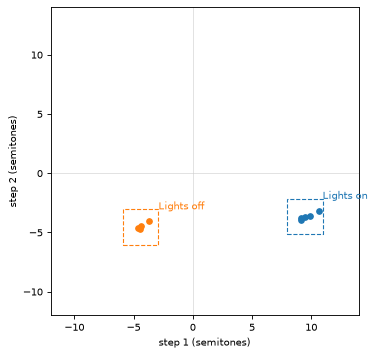

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
colors = dict(zip(PATTERNS, ["C0", "C1"]))
for label, tpl in templates.items():
    ax.add_patch(plt.Rectangle(tpl - TOL_ST, 2 * TOL_ST, 2 * TOL_ST, fill=False, ec=colors[label], ls="--"))
    ax.annotate(label, tpl + TOL_ST, color=colors[label])
for r in recs:
    for ev in r["events"]:
        if device_forwards(ev):
            iv = intervals(ev)[:2]
            ax.plot(*iv, "o", color=colors.get(r["label"], "k"), ms=5)
ax.set_xlabel("step 1 (semitones)"); ax.set_ylabel("step 2 (semitones)")
ax.axhline(0, color="0.8", lw=0.5); ax.axvline(0, color="0.8", lw=0.5); ax.set_aspect("equal")
ax.set_xlim(-12, 14); ax.set_ylim(-12, 14)

## Stress test — whistles over speech

Mix every whistle recording with every speech recording at a range of whistle-to-speech power
ratios and run the full chain (leave-one-out templates). Speech is the hardest negative we have.

In [9]:
def run_chain(x, tpl):
    found = []
    for ev in group_events(segment_notes(frame_features(x))):
        if device_forwards(ev):
            label, _ = server_match(ev, tpl)
            found.append(label or "rejected")
    return found

rms = lambda x: np.sqrt(np.mean(x ** 2))
talking = [r for r in recs if r["label"] == "Talking"]
whistles = [r for r in recs if r["label"] in PATTERNS]
ratios_db = [12, 6, 0, -6, -12]
print("ratio  correct  wrong-label  missed  extra-forwards")
for db in ratios_db:
    correct = wrong = missed = extra = 0
    for w in whistles:
        tpl = build_templates(recs, exclude=w["id"])
        for s in talking:
            sp = np.resize(s["x"], len(w["x"]))
            mix = w["x"] + sp * rms(w["x"]) / rms(sp) * 10 ** (-db / 20)
            found = run_chain(mix, tpl)
            hits = [f for f in found if f in PATTERNS]
            correct += w["label"] in hits
            wrong += any(h != w["label"] for h in hits)
            missed += w["label"] not in hits
            extra += sum(f == "rejected" for f in found)
    print(f"{db:+4d} dB  {correct:4d}     {wrong:4d}       {missed:4d}     {extra:4d}     (of {len(whistles) * len(talking)})")

ratio  correct  wrong-label  missed  extra-forwards
 +12 dB    26        0          1        1     (of 27)


  +6 dB    26        0          1        1     (of 27)
  +0 dB    25        0          2        1     (of 27)


  -6 dB    23        0          4        1     (of 27)
 -12 dB    16        0         11        4     (of 27)


No mix ever produces the *wrong* label or a match on speech alone. Misses grow once speech is as
loud as the whistle. The one miss at +12 dB is instructive: an 80 ms speech fragment at 784 Hz
lands right after "Lights off" and joins the event as a 4th note (by chance also ~−4.3 st, so it
even looks like a continuation). A 4-note event matches no template, so it is rejected — the
conservative failure. Raising the minimum note length to 120 ms was tried and made things worse
(overlapping speech chops real notes below it).

## Device cost

Per 16 ms hop: one 512-point real FFT (~10k MACs with ESP-DSP), a median over ~110 bins (or a
cheaper running noise-floor estimate), and a handful of comparisons. On an ESP32-S3 this is a few
percent of one core. The server sees only ≥3-note tonal events.

## Open issues / next steps

- **Negatives are the real test.** These recordings are minutes; 24/7 needs hours of the room
  (TV, kitchen, appliance beeps, music, someone humming). Add a long-capture mode to the web app
  or stream from the ESP32, and measure forwarded events per hour and false matches per week.
- **Electronic beeps** are pure tones and will pass the gate by design. Likely discriminators
  for the server: perfectly flat pitch (no jitter) and instantaneous onsets.
- **Tolerance** (±1.5 st) is untuned; with more examples, fit per-pattern spread and set it at a
  few σ. Note durations are barely used yet; rhythm is another free axis of discrimination.
- **Mic**: re-record with the ESP32 mic once it arrives — its response and noise floor differ.
- Pitch-contour DTW as a second opinion on the server.